# Introducción

## El presente proyecto analiza los datos sobre la evolución de la tasa de suicidio según la Organización Mundial de la Salud (WHO) entre los años 2000 y 2021
---
###### [Descargar Dataset de la OMS](https://xmart-api-public.who.int/DATA_/RELAY_WHS?$filter=IND_ID%20eq%20%2716BBF41SDGSUICIDE%27&$select=IND_ID,%20IND_CODE,%20IND_UUID,%20IND_PER_CODE,%20DIM_TIME,%20DIM_TIME_TYPE,%20DIM_GEO_CODE_M49,%20DIM_GEO_CODE_TYPE,%20DIM_PUBLISH_STATE_CODE,%20IND_NAME,%20GEO_NAME_SHORT,%20DIM_SEX,%20DIM_AGE,%20RATE_PER_100000_N,%20RATE_PER_100000_NL,%20RATE_PER_100000_NU&$format=csv)
---
## Preguntas


> ### ¿Cómo evolucionó la tasa de suicidios en Argentina entre el 2000 y el 2021?
> ### ¿Cómo se compara Argentina con sus países vecinos en este indicador?
> ### ¿Cuál es la diferencia entre grupos etarios, en Argentina y en el Mundo, en este indicador?








# Exploración




In [111]:
# importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [112]:
# Carga del dataset
# (se carga desde drive pero en caso de que falle se carga directamente de la página de la OMS)
import os

ruta_csv = "/content/drive/MyDrive/RELAY_WHS.csv"
url_oms = "https://xmart-api-public.who.int/DATA_/RELAY_WHS?$filter=IND_ID%20eq%20%2716BBF41SDGSUICIDE%27&$select=IND_ID,%20IND_CODE,%20IND_UUID,%20IND_PER_CODE,%20DIM_TIME,%20DIM_TIME_TYPE,%20DIM_GEO_CODE_M49,%20DIM_GEO_CODE_TYPE,%20DIM_PUBLISH_STATE_CODE,%20IND_NAME,%20GEO_NAME_SHORT,%20DIM_SEX,%20DIM_AGE,%20RATE_PER_100000_N,%20RATE_PER_100000_NL,%20RATE_PER_100000_NU&$format=csv"

if os.path.exists(ruta_csv):
    print("Cargando dataset de la OMS desde Google Drive...")
    df_mental_health = pd.read_csv(ruta_csv)
else:
    print("Google Drive no montado o archivo no encontrado. Descargando dataset desde la URL pública de la OMS...")
    df_mental_health = pd.read_csv(url_oms)

Cargando dataset de la OMS desde Google Drive...


In [113]:
# primeras filas
df_mental_health.head()

,IND_ID,IND_CODE,IND_UUID,IND_PER_CODE,DIM_TIME,DIM_TIME_TYPE,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,DIM_PUBLISH_STATE_CODE,IND_NAME,GEO_NAME_SHORT,DIM_SEX,DIM_AGE,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU
0,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2005,YEAR,462,COUNTRY,PUBLISHED,Suicide deaths,Maldives,MALE,TOTAL,4.040737,2.619692,5.730590
1,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2005,YEAR,462,COUNTRY,PUBLISHED,Suicide deaths,Maldives,TOTAL,TOTAL,2.449645,1.593509,3.558703
2,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2005,YEAR,466,COUNTRY,PUBLISHED,Suicide deaths,Mali,FEMALE,TOTAL,2.744844,1.390052,4.388311
3,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2005,YEAR,466,COUNTRY,PUBLISHED,Suicide deaths,Mali,MALE,TOTAL,5.091353,2.655092,9.342534
4,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2005,YEAR,466,COUNTRY,PUBLISHED,Suicide deaths,Mali,TOTAL,TOTAL,3.928525,2.024647,6.875605


In [114]:
# útlimas filas
df_mental_health.tail()

,IND_ID,IND_CODE,IND_UUID,IND_PER_CODE,DIM_TIME,DIM_TIME_TYPE,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,DIM_PUBLISH_STATE_CODE,IND_NAME,GEO_NAME_SHORT,DIM_SEX,DIM_AGE,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU
18930,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2021,YEAR,364,COUNTRY,PUBLISHED,Suicide deaths,Iran (Islamic Republic of),MALE,Y30T49,7.186636,NaN,NaN
18931,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2021,YEAR,300,COUNTRY,PUBLISHED,Suicide deaths,Greece,FEMALE,Y30T49,1.484835,NaN,NaN
18932,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2021,YEAR,300,COUNTRY,PUBLISHED,Suicide deaths,Greece,MALE,Y30T49,8.671985,NaN,NaN
18933,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2021,YEAR,392,COUNTRY,PUBLISHED,Suicide deaths,Japan,TOTAL,Y30T49,20.315399,NaN,NaN
18934,16BBF41SDGSUICIDE,SDGSUICIDE,16BBF41,SDGSUICIDE,2021,YEAR,398,COUNTRY,PUBLISHED,Suicide deaths,Kazakhstan,FEMALE,Y30T49,5.570343,NaN,NaN


In [115]:
# cantidad de filas y columnas
df_mental_health.shape

(18935, 16)

In [116]:
# información básica sobre tipo, cantidad y calidad de datos
df_mental_health.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18935 entries, 0 to 18934
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   IND_ID                  18935 non-null  object 
 1   IND_CODE                18935 non-null  object 
 2   IND_UUID                18935 non-null  object 
 3   IND_PER_CODE            18935 non-null  object 
 4   DIM_TIME                18935 non-null  int64  
 5   DIM_TIME_TYPE           18935 non-null  object 
 6   DIM_GEO_CODE_M49        18935 non-null  int64  
 7   DIM_GEO_CODE_TYPE       18935 non-null  object 
 8   DIM_PUBLISH_STATE_CODE  18935 non-null  object 
 9   IND_NAME                18935 non-null  object 
 10  GEO_NAME_SHORT          18935 non-null  object 
 11  DIM_SEX                 18935 non-null  object 
 12  DIM_AGE                 18935 non-null  object 
 13  RATE_PER_100000_N       18935 non-null  float64
 14  RATE_PER_100000_NL      12916 non-null

In [117]:
# tipos de datos en cada columna
df_mental_health.dtypes

,0
IND_ID,object
IND_CODE,object
IND_UUID,object
IND_PER_CODE,object
DIM_TIME,int64
DIM_TIME_TYPE,object
DIM_GEO_CODE_M49,int64
DIM_GEO_CODE_TYPE,object
DIM_PUBLISH_STATE_CODE,object
IND_NAME,object


In [118]:
# Estadísticas numéricas
df_mental_health.describe()

,DIM_TIME,DIM_GEO_CODE_M49,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU
count,18935.000000,18935.000000,18935.000000,12916.000000,12916.000000
mean,2013.833589,446.957539,10.459298,7.331640,12.389570
std,7.169670,267.313282,11.362481,8.075548,10.927878
min,2000.000000,1.000000,0.000000,0.000000,0.000000
25%,2008.000000,214.000000,3.556997,2.251270,5.197813
50%,2016.000000,430.000000,6.979494,4.712155,9.540041
75%,2021.000000,686.000000,13.084199,9.545386,15.833875
max,2021.000000,958.000000,160.594452,92.247922,97.060599


# Limpieza

In [119]:
# identificar valores nulos
df_mental_health.isnull().sum()

,0
IND_ID,0
IND_CODE,0
IND_UUID,0
IND_PER_CODE,0
DIM_TIME,0
DIM_TIME_TYPE,0
DIM_GEO_CODE_M49,0
DIM_GEO_CODE_TYPE,0
DIM_PUBLISH_STATE_CODE,0
IND_NAME,0


Hay dos columnas con valores faltantes, 6019 cada una. Son el límite inferior (RATE_PER_100000_NL) y el límite superior (RATE_PER_100000_NU) estadístico, no afectan mi análisis, voy a usar la columna tasa central estimada (RATE_PER_100000_N).

In [120]:
# buscar registros duplicados
df_mental_health.duplicated().sum()

np.int64(0)

In [121]:
# Verificar la distribución de los nombres del indicador para asegurar que todos correspondan a 'Suicide deaths'
df_mental_health['IND_NAME'].value_counts()

,count
IND_NAME,
Suicide deaths,18935


In [122]:
# Calcular la matriz de correlación de Pearson para todas las variables numéricas del dataset de salud mental
df_mental_health.corr(numeric_only=True)

,DIM_TIME,DIM_GEO_CODE_M49,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU
DIM_TIME,1.000000,-0.026548,0.049522,-0.068150,-0.037824
DIM_GEO_CODE_M49,-0.026548,1.000000,0.027880,0.023856,0.014088
RATE_PER_100000_N,0.049522,0.027880,1.000000,0.977401,0.974246
RATE_PER_100000_NL,-0.068150,0.023856,0.977401,1.000000,0.911061
RATE_PER_100000_NU,-0.037824,0.014088,0.974246,0.911061,1.000000


### Revisión de columnas constantes y valores anómalos
Se verificará si existen columnas con un solo valor (constantes) y se revisarán las distribuciones y categorías para identificar datos extraños.

In [123]:
# 1. Revisión de columnas constantes
print("--- COLUMNAS CONSTANTES ---")
columnas_constantes = [col for col in df_mental_health.columns if df_mental_health[col].nunique() == 1]

if columnas_constantes:
    print(f"Se encontraron {len(columnas_constantes)} columnas constantes:")
    for col in columnas_constantes:
        print(f" - {col}: {df_mental_health[col].unique()[0]}")
else:
    print("No se encontraron columnas constantes.")

print("\n" + "="*40 + "\n")

# 2. Revisión de valores categóricos fuera de lo esperable
print("--- VALORES EN COLUMNAS CATEGÓRICAS CLAVE ---")
# Filtramos algunas columnas categóricas de interés para ver si hay categorías extrañas
columnas_cat_interes = ['DIM_SEX', 'DIM_AGE', 'DIM_TIME_TYPE', 'DIM_PUBLISH_STATE_CODE']

for col in columnas_cat_interes:
    print(f"\nValores únicos en '{col}':")
    print(df_mental_health[col].value_counts())

print("\n" + "="*40 + "\n")

# 3. Revisión de valores numéricos fuera de rangos lógicos
print("--- RESUMEN DE VARIABLES NUMÉRICAS ---")
# Verificamos por ejemplo que el año (DIM_TIME) tenga sentido y que las tasas no sean negativas
display(df_mental_health[['DIM_TIME', 'RATE_PER_100000_N']].describe())

--- COLUMNAS CONSTANTES ---
Se encontraron 7 columnas constantes:
 - IND_ID: 16BBF41SDGSUICIDE
 - IND_CODE: SDGSUICIDE
 - IND_UUID: 16BBF41
 - IND_PER_CODE: SDGSUICIDE
 - DIM_TIME_TYPE: YEAR
 - DIM_PUBLISH_STATE_CODE: PUBLISHED
 - IND_NAME: Suicide deaths


--- VALORES EN COLUMNAS CATEGÓRICAS CLAVE ---

Valores únicos en 'DIM_SEX':
DIM_SEX
TOTAL     6317
MALE      6315
FEMALE    6303
Name: count, dtype: int64

Valores únicos en 'DIM_AGE':
DIM_AGE
TOTAL     12916
Y_GE70      553
Y50T69      549
Y40T49      549
Y30T49      549
Y10T19      548
Y50T59      548
Y30T39      547
Y20T29      545
Y15T29      545
Y60T69      545
Y15T19      541
Name: count, dtype: int64

Valores únicos en 'DIM_TIME_TYPE':
DIM_TIME_TYPE
YEAR    18935
Name: count, dtype: int64

Valores únicos en 'DIM_PUBLISH_STATE_CODE':
DIM_PUBLISH_STATE_CODE
PUBLISHED    18935
Name: count, dtype: int64


--- RESUMEN DE VARIABLES NUMÉRICAS ---


,DIM_TIME,RATE_PER_100000_N
count,18935.000000,18935.000000
mean,2013.833589,10.459298
std,7.169670,11.362481
min,2000.000000,0.000000
25%,2008.000000,3.556997
50%,2016.000000,6.979494
75%,2021.000000,13.084199
max,2021.000000,160.594452


#####Columnas constantes: El análisis encontró las siguientes columnas constantes (7):
 - IND_ID: 16BBF41SDGSUICIDE
 - IND_CODE: SDGSUICIDE
 - IND_UUID: 16BBF41
 - IND_PER_CODE: SDGSUICIDE
 - DIM_TIME_TYPE: YEAR
 - DIM_PUBLISH_STATE_CODE: PUBLISHED
 - IND_NAME: Suicide deaths

 Cada una de estas columnas contiene exactamente el mismo valor para todas las filas del dataset, no aportan valor estadístico y se pueden descartar para el análisis.
#####Valores categóricos: Las variables demográficas muestran datos limpios. DIM_SEX tiene los 3 valores esperados (MALE, FEMALE, TOTAL) y DIM_AGE contiene los rangos etarios estándar de la OMS sin categorías extrañas o mal escritas.
#####Valores numéricos: Se verifica que la dimensión temporal (DIM_TIME) va correctamente del año 2000 al 2021. Además, la tasa de suicidios (RATE_PER_100000_N) tiene un mínimo de 0 y un máximo de ~160.6, lo cual confirma que no hay valores negativos ilógicos.

A continuación se eliminarán las columnas constantes

In [124]:
# Eliminar columnas constantes
columnas_constantes_eliminar = ['IND_ID', 'IND_CODE', 'IND_UUID', 'IND_PER_CODE', 'DIM_TIME_TYPE', 'DIM_PUBLISH_STATE_CODE', 'IND_NAME']
df_mental_health_clean = df_mental_health.drop(columns=columnas_constantes_eliminar)

df_argentina = df_mental_health_clean[df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina'] #aquí se filtra la información de Argentina
df_argentina

,DIM_TIME,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,GEO_NAME_SHORT,DIM_SEX,DIM_AGE,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU
85,2004,32,COUNTRY,Argentina,MALE,TOTAL,14.031042,12.473875,15.566666
86,2004,32,COUNTRY,Argentina,TOTAL,TOTAL,8.747168,7.747822,9.723411
110,2004,32,COUNTRY,Argentina,FEMALE,TOTAL,3.607274,3.158440,4.048765
787,2010,32,COUNTRY,Argentina,TOTAL,TOTAL,8.541667,7.574814,9.534885
796,2010,32,COUNTRY,Argentina,FEMALE,TOTAL,3.197463,2.807208,3.589472
...,...,...,...,...,...,...,...,...,...
18123,2021,32,COUNTRY,Argentina,TOTAL,Y30T49,8.716017,NaN,NaN
18132,2021,32,COUNTRY,Argentina,FEMALE,Y30T49,3.680413,NaN,NaN
18204,2021,32,COUNTRY,Argentina,FEMALE,Y10T19,4.277303,NaN,NaN
18205,2021,32,COUNTRY,Argentina,MALE,Y10T19,7.056337,NaN,NaN


In [125]:
# Identificar y ordenar de forma descendente la cantidad de valores faltantes por columna en el dataset limpio
df_mental_health_clean.isna().sum().sort_values(ascending=False)

,0
RATE_PER_100000_NL,6019
RATE_PER_100000_NU,6019
DIM_TIME,0
DIM_GEO_CODE_M49,0
DIM_GEO_CODE_TYPE,0
DIM_SEX,0
GEO_NAME_SHORT,0
RATE_PER_100000_N,0
DIM_AGE,0


In [126]:
# Verificar la existencia de valores nulos en el dataset limpio
dup_total = df_mental_health_clean.duplicated().sum()
dup_total

np.int64(0)

# Análisis

Aquí le pedí a la IA que busque el diccionario de datos para este dataset y que lo incluya como un Markdown

## 📖 Diccionario de Datos: Tasas de Suicidio (OMS / ODS)

Este conjunto de datos contiene información estandarizada por la Organización Mundial de la Salud (OMS) para el monitoreo del indicador de **mortalidad por suicidio** dentro de los Objetivos de Desarrollo Sostenible (ODS/SDG).

---

### ሄ Identificadores del Indicador
* **`IND_ID`**: Identificador único que combina el código del indicador y el contexto. (Ej. `16BBF41SDGSUICIDE`).
* **`IND_CODE`**: Código estandarizado del indicador de los ODS. (Ej. `SDGSUICIDE`).
* **`IND_UUID`**: Identificador único universal del registro del indicador.
* **`IND_PER_CODE`**: Código de periodicidad o categoría de presentación del indicador.
* **`IND_NAME`**: Nombre oficial del indicador. En este dataset corresponde a `Suicide deaths` (Muertes por suicidio).

### ሸ Dimensión Temporal y Estado
* **`DIM_TIME`**: Año del registro estadístico (Ej. `2005`).
* **`DIM_TIME_TYPE`**: Tipo de período temporal utilizado. En este caso, `YEAR` (Anual).
* **`DIM_PUBLISH_STATE_CODE`**: Estado de validación y publicación del dato. Habitualmente figura como `PUBLISHED`.

### ሩ Dimensión Geográfica
* **`DIM_GEO_CODE_M49`**: Código numérico estándar de la ONU (M49) para identificar países y regiones geográficas.
* **`DIM_GEO_CODE_TYPE`**: Tipo de división geográfica analizada. En este dataset es `COUNTRY` (País).
* **`GEO_NAME_SHORT`**: Nombre común o corto del país en inglés (Ej. `Maldives`).

### ኁ Dimensión Demográfica
* **`DIM_SEX`**: Segmentación por sexo biológico. Puede tomar valores como `MALE` (Hombres), `FEMALE` (Mujeres) o `TOTAL` (Ambos sexos).
* **`DIM_AGE`**: Grupo de edad analizado. Incluye diversos rangos etarios como `Y10T19` (10-19 años), `Y20T29` (20-29 años), `Y30T49` (30-49 años), `Y50T69` (50-69 años) y `Y70PLUS` (70+ años), además de la categoría `TOTAL` (que abarca todas las edades de la población). Esta información sólo está disponible para el año 2021.

---

### ኄ Variables Métricas y Estadísticas (Tasa por cada 100,000 habitantes)

| Nombre de la Columna | Tipo de Dato | Descripción |
| :--- | :--- | :--- |
| **`RATE_PER_100000_N`** | `Float` (Numérico) | **Tasa central estimada**: Es el valor promedio o estimación puntual del indicador por cada 100,000 personas. |
| **`RATE_PER_100000_NL`** | `Float` (Numérico) | **Límite Inferior (*Numeric Lower*)**: El valor mínimo esperado dentro del intervalo de confianza estadística (Margen de error inferior). |
| **`RATE_PER_100000_NU`** | `Float` (Numérico) | **Límite Superior (*Numeric Upper*)**: El valor máximo esperado dentro del intervalo de confianza estadística (Margen de error superior). |

> ረ *Nota sobre datos faltantes:* Las columnas `_NL` y `_NU` presentan valores nulos (`NaN`) en aproximadamente el 32% del dataset. Esto ocurre de manera habitual en datos de la OMS debido a diferencias en los modelos epidemiológicos de cada país o por el tamaño reducido de ciertas poblaciones. No afecta el análisis descriptivo de la tasa central (`_N`).

## Primera pregunta: ¿Cómo evolucionó la tasa de suicidios en Argentina entre 2000 y 2021?

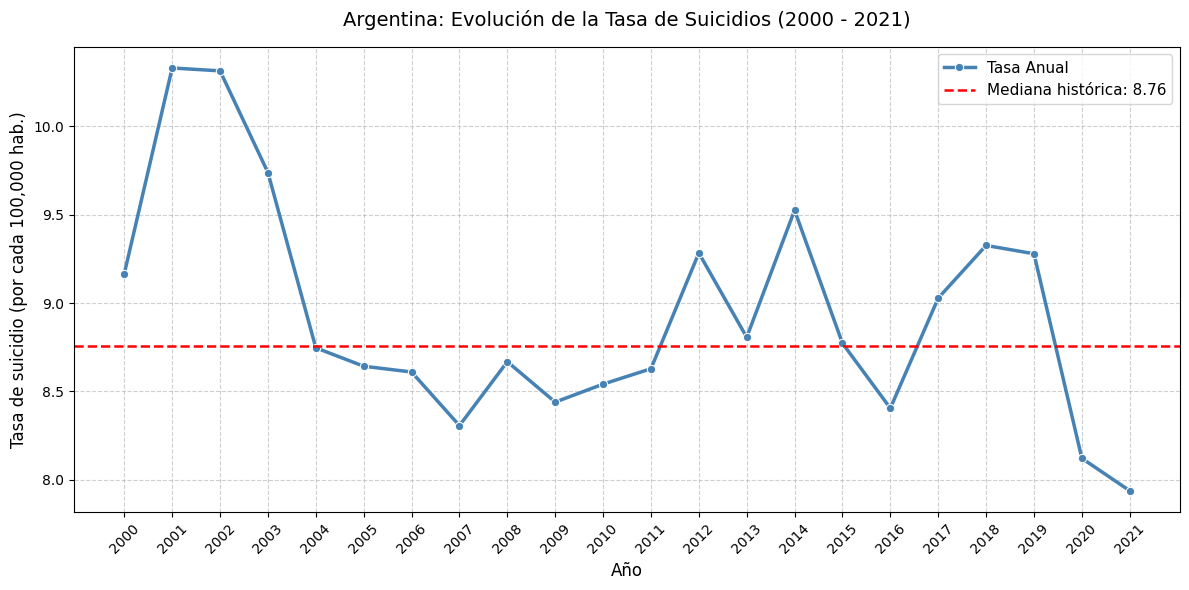

In [127]:
# Creación de un gráfico de líneas para graficar la evolución de la tasa de suiciodios en Argentina
df_arg_evolucion = df_argentina[
    (df_argentina['DIM_SEX'] == 'TOTAL') &
    (df_argentina['DIM_AGE'] == 'TOTAL')
].sort_values(by='DIM_TIME')

mediana_tasa = df_arg_evolucion['RATE_PER_100000_N'].median()

plt.figure(figsize=(12, 6))
sns.lineplot(data=df_arg_evolucion, x='DIM_TIME', y='RATE_PER_100000_N', marker='o', color='steelblue', linewidth=2.5, label='Tasa Anual')

# Inclusión de la mediana en el gráfico
plt.axhline(mediana_tasa, color='red', linestyle='--', linewidth=1.8, label=f'Mediana histórica: {mediana_tasa:.2f}')

plt.title('Argentina: Evolución de la Tasa de Suicidios (2000 - 2021)', fontsize=14, pad=15)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Tasa de suicidio (por cada 100,000 hab.)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(range(2000, 2022, 1), rotation=45)
plt.legend(fontsize=11)

plt.tight_layout()
plt.show()

La tasa de suicidios en Argentina entre el año 2000 y el 2021 tuvo una mediana de 8.76 cada 100.000 habitantes.

> Se observa un pico entre los años 2001 y 2002, se puede suponer que la crisis económica tuvo que ver con este hecho.

> Entre 2019 y 2021 se observa un descenso pronunciado, llegando a estar por debajo de 8 muertes por suicidio cada 100.000 habitantes en 2021





##Segunda pregunta: ¿Cómo se compara Argentina con sus países vecinos en este indicador?

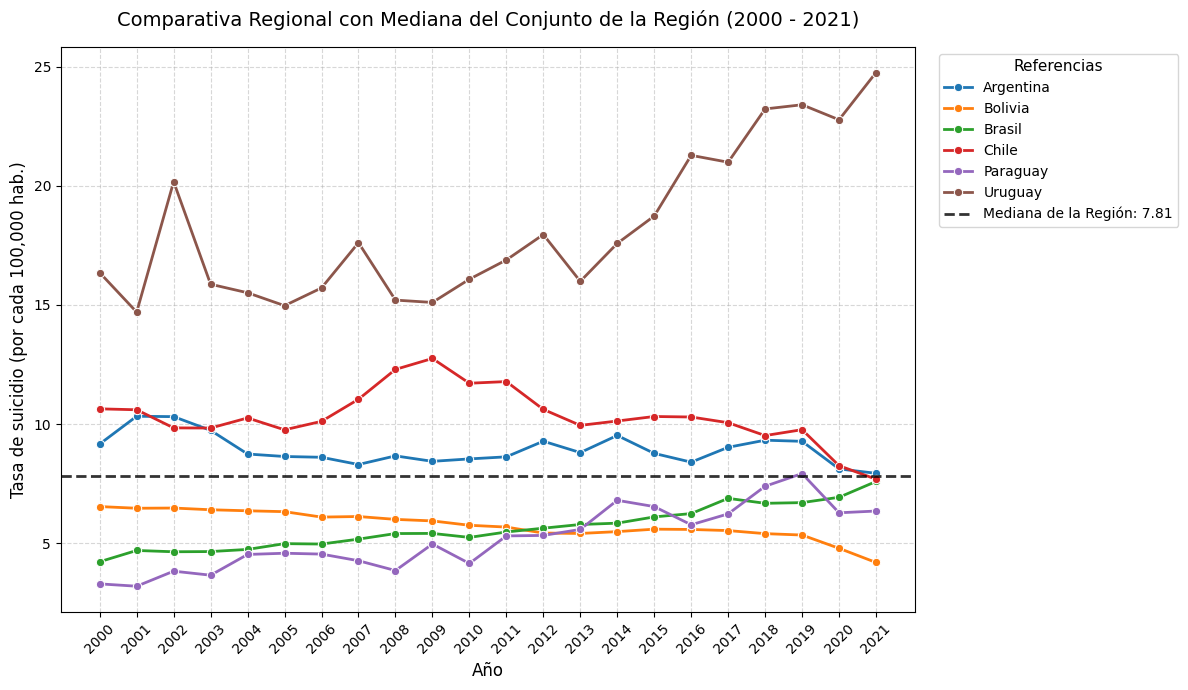

In [128]:
# Se seleccionan los países para la comparación
paises_comparacion = [
    'Argentina',
    'Brazil',
    'Chile',
    'Paraguay',
    'Uruguay',
    'Bolivia (Plurinational State of)'
]

df_vecinos = df_mental_health_clean[
    (df_mental_health_clean['GEO_NAME_SHORT'].isin(paises_comparacion)) &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'] == 'TOTAL')
].sort_values(by=['GEO_NAME_SHORT', 'DIM_TIME'])

# Se simplifican los nombres para el gráfico
mapeo_nombres_es = {
    'Argentina': 'Argentina',
    'Brazil': 'Brasil',
    'Chile': 'Chile',
    'Paraguay': 'Paraguay',
    'Uruguay': 'Uruguay',
    'Bolivia (Plurinational State of)': 'Bolivia'
}
df_vecinos['Pais'] = df_vecinos['GEO_NAME_SHORT'].map(mapeo_nombres_es)

# se calcula la mediana para la región
mediana_regional = df_vecinos['RATE_PER_100000_N'].median()

# gráfico de líneas
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=df_vecinos,
    x='DIM_TIME',
    y='RATE_PER_100000_N',
    hue='Pais',
    marker='o',
    linewidth=2
)

plt.axhline(
    mediana_regional,
    color='black',
    linestyle='--',
    alpha=0.8,
    linewidth=2,
    label=f'Mediana de la Región: {mediana_regional:.2f}'
)

plt.title('Comparativa Regional con Mediana del Conjunto de la Región (2000 - 2021)', fontsize=14, pad=15)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Tasa de suicidio (por cada 100,000 hab.)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(range(2000, 2022, 1), rotation=45)

plt.legend(title='Referencias', fontsize=10, title_fontsize=11, loc='upper left', bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

Argentina está ligeramente por encima de la mediana de la región. Son llamativos los valores de la tasa de suicidio en Uruguay.

## Tercera pregunta: ¿Cuál es la diferencia entre grupos etarios, en Argentina y en el Mundo, en este indicador?

### Comparación de Tasas de Suicidio por Grupo Etario (2021): Argentina vs. Promedio de Países

> *Nota metodológica: La referencia "Promedio de Países" representa un promedio simple de las tasas de todos los países disponibles en el dataset para cada grupo etario. Al no contar con los datos de población total de cada país para realizar una ponderación poblacional, este valor le asigna el mismo peso al indicador de cada país, independientemente de su población.*


In [129]:
# Se identifican los grupos etarios que se incluirán en la comparación
grupos_limpios_reales = ['Y10T19', 'Y20T29', 'Y30T49', 'Y50T69', 'Y_GE70']

# Se simplifican los nombres de los grupos etarios
mapeo_edades = {
    'Y10T19': '10-19 años',
    'Y20T29': '20-29 años',
    'Y30T49': '30-49 años',
    'Y50T69': '50-69 años',
    'Y_GE70': '70+ años'
}

# Se ordena la presentación de los grupos etarios en el gráfico
orden_edades = ['10-19 años', '20-29 años', '30-49 años', '50-69 años', '70+ años']

df_arg_age = df_mental_health_clean[
    (df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina') &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_limpios_reales))
].copy()
df_arg_age['Ambito'] = 'Argentina'
df_arg_age['Grupo Etario'] = df_arg_age['DIM_AGE'].map(mapeo_edades)

df_world_age_recent = df_mental_health_clean[
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_limpios_reales))
].groupby('DIM_AGE')['RATE_PER_100000_N'].mean().reset_index()

df_world_age_recent['Ambito'] = 'Promedio de Países'
df_world_age_recent['Grupo Etario'] = df_world_age_recent['DIM_AGE'].map(mapeo_edades)

estructura_base = []
for g in orden_edades:
    for a in ['Argentina', 'Promedio de Países']:
        estructura_base.append({'Grupo Etario': g, 'Ambito': a, 'RATE_PER_100000_N': 0.0})
df_comparativa_2021 = pd.DataFrame(estructura_base)

for _, row in df_arg_age.iterrows():
    df_comparativa_2021.loc[
        (df_comparativa_2021['Grupo Etario'] == row['Grupo Etario']) &
        (df_comparativa_2021['Ambito'] == 'Argentina'),
        'RATE_PER_100000_N'
    ] = float(row['RATE_PER_100000_N'])

for _, row in df_world_age_recent.iterrows():
    df_comparativa_2021.loc[
        (df_comparativa_2021['Grupo Etario'] == row['Grupo Etario']) &
        (df_comparativa_2021['Ambito'] == 'Promedio de Países'),
        'RATE_PER_100000_N'
    ] = float(row['RATE_PER_100000_N'])

df_comparativa_2021['RATE_PER_100000_N'] = df_comparativa_2021['RATE_PER_100000_N'].astype(float)

# Se grafica utilizando un scatter plot
fig_dot = px.scatter(
    df_comparativa_2021,
    x='RATE_PER_100000_N',
    y='Grupo Etario',
    color='Ambito',
    labels={
        'RATE_PER_100000_N': 'Tasa por 100,000 habitantes',
        'Grupo Etario': 'Grupo de Edad',
        'Ambito': 'Ámbito'
    },
    title='Comparación de Tasas de Suicidio por Edad (2021): Argentina vs. Promedio de Países',
    color_discrete_map={'Argentina': '#3182bd', 'Promedio de Países': '#e6550d'},
    category_orders={'Grupo Etario': orden_edades}
)

fig_dot.update_traces(marker=dict(size=14, opacity=0.85, line=dict(width=1.5, color='DarkSlateGrey')))

fig_dot.update_layout(
    title_font_size=16,
    hovermode='y unified',
    margin=dict(l=40, r=40, t=60, b=40),
    xaxis_title="Tasa (casos por cada 100k habitantes)",
    yaxis_title="Grupo de Edad",
    yaxis={
        'type': 'category',
        'categoryorder': 'array',
        'categoryarray': orden_edades
    },
    showlegend=True
)

fig_dot.show()


Vemos que la tasa de suicidio promedio de países se incrementa con la edad. En Argentina se da la particularidad de estar por encima de la media en los rangos de 10 a 19 y 20 a 29 años, siendo particularmente alta en este último grupo.
A partir de los 30 años la tasa Argentina está por debajo del promedio de países, diferencia que se profundiza a mayor edad.

In [130]:
registros_arg_70 = df_mental_health_clean[
    (df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina') &
    (df_mental_health_clean['DIM_TIME'] == 2021) &
    (df_mental_health_clean['DIM_AGE'] == 'Y70PLUS')
]

display(registros_arg_70)

,DIM_TIME,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,GEO_NAME_SHORT,DIM_SEX,DIM_AGE,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU


### Comparativa Internacional de Tasas de Suicidio por Grupo Etario (2021)

In [131]:
import plotly.graph_objects as go

# Aquí se agregan algunos países representativos a la comparación
paises_seleccionados = {
    'Argentina': 'Argentina',
    'Brazil': 'Brasil',
    'Chile': 'Chile',
    'Mexico': 'México',
    'Spain': 'España',
    'France': 'Francia',
    'United States of America': 'Estados Unidos'
}

df_paises_age = df_mental_health_clean[
    (df_mental_health_clean['DIM_TIME'] == 2021) &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['GEO_NAME_SHORT'].isin(paises_seleccionados.keys())) &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_limpios_reales))
].copy()

df_paises_age['Ambito'] = df_paises_age['GEO_NAME_SHORT'].map(paises_seleccionados)

df_world_ref = df_world_age_recent.copy()
df_world_ref['Ambito'] = 'Promedio de Países'

df_comparativa_global = pd.concat([
    df_paises_age[['DIM_AGE', 'RATE_PER_100000_N', 'Ambito']],
    df_world_ref[['DIM_AGE', 'RATE_PER_100000_N', 'Ambito']]
])

df_comparativa_global['Grupo Etario'] = df_comparativa_global['DIM_AGE'].map(mapeo_edades)
df_comparativa_global['Grupo Etario'] = pd.Categorical(df_comparativa_global['Grupo Etario'], categories=orden_edades, ordered=True)

paises_resto = sorted([p for p in paises_seleccionados.values() if p != 'Argentina'])
orden_leyenda = ['Argentina', 'Promedio de Países'] + paises_resto

df_comparativa_global['Ambito'] = pd.Categorical(
    df_comparativa_global['Ambito'],
    categories=orden_leyenda,
    ordered=True
)

df_comparativa_global = df_comparativa_global.sort_values(by=['Grupo Etario', 'Ambito'])

fig_global_dot = px.scatter(
    df_comparativa_global,
    x='RATE_PER_100000_N',
    y='Grupo Etario',
    color='Ambito',
    labels={
        'RATE_PER_100000_N': 'Tasa por 100,000 habitantes',
        'Grupo Etario': 'Grupo de Edad',
        'Ambito': 'País / Referencia'
    },
    title='Comparativa Internacional: Tasas de Suicidio por Edad (2021)',
    color_discrete_map={
        'Argentina': '#00a8e8',
        'Promedio de Países': '#333333',
        'Brasil': '#2ec4b6',
        'Chile': '#e71d36',
        'México': '#ff9f1c',
        'España': '#9b5de5',
        'Francia': '#f15bb5',
        'Estados Unidos': '#00f5d4'
    },
    category_orders={'Ambito': orden_leyenda, 'Grupo Etario': orden_edades}
)

df_world_line = df_comparativa_global[df_comparativa_global['Ambito'] == 'Promedio de Países'].sort_values(by='Grupo Etario')

fig_global_dot.add_trace(
    go.Scatter(
        x=df_world_line['RATE_PER_100000_N'],
        y=df_world_line['Grupo Etario'],
        mode='lines',
        name='Eje Promedio de Países',
        line=dict(color='#555555', width=2, dash='dash'),
        hoverinfo='skip',
        showlegend=True
    )
)

fig_global_dot.update_traces(marker=dict(size=12, opacity=0.9, line=dict(width=1, color='White')), selector=dict(mode='markers'))

for trace in fig_global_dot.data:
    if trace.name == 'Argentina':
        trace.marker.size = 17
        trace.marker.line.color = 'black'
        trace.marker.line.width = 2
    elif trace.name == 'Promedio de Países':
        trace.marker.size = 12
        trace.marker.symbol = 'circle'

fig_global_dot.update_layout(
    title_font_size=16,
    hovermode='y unified',
    height=600,
    margin=dict(l=40, r=40, t=60, b=40),
    xaxis_title="Tasa (casos por cada 100k habitantes)",
    yaxis_title="Grupo de Edad",
    yaxis={
        'type': 'category',
        'categoryorder': 'array',
        'categoryarray': orden_edades
    },
    showlegend=True
)

fig_global_dot.show()

Incluyendo varios países a la comparativa, vemos que la situación de Argentina con los jóvenes es compartida con Estados Unidos y México. Particularmente el comportamiendo del indicador de Argentina y México presenta un recorrido similar en los diferentes grupos etarios.

### Comparativa Internacional de Tasas de Suicidio por Grupo Etario utilizando la Mediana de Países (2021)

In [132]:
# cálculo de mediana
df_world_median = df_mental_health_clean[
    (df_mental_health_clean['DIM_TIME'] == 2021) &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_limpios_reales))
].groupby('DIM_AGE')['RATE_PER_100000_N'].median().reset_index()

df_world_median['Ambito'] = 'Mediana de Países'

df_paises_age_2021 = df_paises_age.copy()

df_comparativa_mediana = pd.concat([
    df_paises_age_2021[['DIM_AGE', 'RATE_PER_100000_N', 'Ambito']],
    df_world_median[['DIM_AGE', 'RATE_PER_100000_N', 'Ambito']]
])

df_comparativa_mediana['Grupo Etario'] = df_comparativa_mediana['DIM_AGE'].map(mapeo_edades)
df_comparativa_mediana['Grupo Etario'] = pd.Categorical(df_comparativa_mediana['Grupo Etario'], categories=orden_edades, ordered=True)

orden_leyenda_mediana = ['Argentina', 'Mediana de Países'] + paises_resto
df_comparativa_mediana['Ambito'] = pd.Categorical(
    df_comparativa_mediana['Ambito'],
    categories=orden_leyenda_mediana,
    ordered=True
)

df_comparativa_mediana = df_comparativa_mediana.sort_values(by=['Grupo Etario', 'Ambito'])

fig_global_median_dot = px.scatter(
    df_comparativa_mediana,
    x='RATE_PER_100000_N',
    y='Grupo Etario',
    color='Ambito',
    labels={
        'RATE_PER_100000_N': 'Tasa por 100,000 habitantes',
        'Grupo Etario': 'Grupo de Edad',
        'Ambito': 'País / Referencia'
    },
    title='Comparativa Internacional: Tasas de Suicidio por Edad (Referencia: Mediana de Países)',
    color_discrete_map={
        'Argentina': '#00a8e8',
        'Mediana de Países': '#333333',
        'Brasil': '#2ec4b6',
        'Chile': '#e71d36',
        'México': '#ff9f1c',
        'España': '#9b5de5',
        'Francia': '#f15bb5',
        'Estados Unidos': '#00f5d4'
    },
    category_orders={'Ambito': orden_leyenda_mediana, 'Grupo Etario': orden_edades}
)

df_world_median_line = df_comparativa_mediana[df_comparativa_mediana['Ambito'] == 'Mediana de Países'].sort_values(by='Grupo Etario')

fig_global_median_dot.add_trace(
    go.Scatter(
        x=df_world_median_line['RATE_PER_100000_N'],
        y=df_world_median_line['Grupo Etario'],
        mode='lines',
        name='Eje Mediana de Países',
        line=dict(color='#555555', width=2, dash='dash'),
        hoverinfo='skip',
        showlegend=True
    )
)

fig_global_median_dot.update_traces(marker=dict(size=12, opacity=0.9, line=dict(width=1, color='White')), selector=dict(mode='markers'))

for trace in fig_global_median_dot.data:
    if trace.name == 'Argentina':
        trace.marker.size = 17
        trace.marker.line.color = 'black'
        trace.marker.line.width = 2
    elif trace.name == 'Mediana de Países':
        trace.marker.size = 12
        trace.marker.symbol = 'circle'

fig_global_median_dot.update_layout(
    title_font_size=16,
    hovermode='y unified',
    height=600,
    margin=dict(l=40, r=40, t=60, b=40),
    xaxis_title="Tasa (casos por cada 100k habitantes)",
    yaxis_title="Grupo de Edad",
    yaxis={
        'type': 'category',
        'categoryorder': 'array',
        'categoryarray': orden_edades
    },
    showlegend=True
)

fig_global_median_dot.show()

Utilizando la mediana en lugar del promedio, el comportamiento del indicador es similar

#Cierre:

> Tomando en cuenta la evolución en el tiempo, en Argentina, el comportamiento de la tasa de suicidios pareciera tener relación con la situación económica, como se evidencia en los altos valores del 2001 y 2002. Esto requiere mayor investigación que permita la correlación con indicadores económicos.

> El grupo etario con mayor tasa de suicidios en Argentina en el último año del que se disponen datos (2021) es el de los 20 a los 29 años. Esto contradice la mediana de países en la que la mayor tasa de suicidios suele ubicarse por encima de los 60 años.

> Luego del análisis de los datos se infiere que las políticas públicas referidas a la problemática del suicidio en Argentina deberían enfocarse principalmente en los jóvenes, particularmente en el rango etario de 20 a 29 años, y también entre los 10 y 19 años.

# Anexo
## Dos líneas de investigación surgieron a partir del análisis de datos:

> Ajustar la comparación a partir de incluir la población de cada país en el dataset, con lo cual poder tener un "promedio mundial ponderado" que sea más representativo, y verificar si eso modifica el análisis.


> Incorporar algún indicador económico para verificar o no la correlación con la evolución de la tasa de suicidios en Argentina con la evolución de la economía.





### Gráfico de Comparación Corregido: Argentina vs. Promedio Mundial Ponderado (2021)

### Incorporación de Datos de Población Mundial para Comparaciones Ponderadas

Para realizar comparaciones globales válidas, descargaremos la **Población Total** (`SP.POP.TOTL`) del Banco Mundial para todos los países del mundo entre 2000 y 2021. Esto nos permitirá calcular el promedio ponderado mundial de la tasa de suicidio.

In [133]:
from pandas_datareader import wb
import urllib.error

print("Descargando datos de población mundial desde la API del Banco Mundial...")
try:
    # Descargamos la población de todos los países ('all') para los años del análisis
    df_poblacion = wb.download(
        indicator='SP.POP.TOTL',
        country='all',
        start=2000,
        end=2021
    ).reset_index()

    # Renombrar columnas y dar formato
    df_poblacion = df_poblacion.rename(columns={'SP.POP.TOTL': 'Poblacion_Total', 'year': 'DIM_TIME'})
    df_poblacion['DIM_TIME'] = df_poblacion['DIM_TIME'].astype(int)

    # Guardamos una copia del nombre original de la API del Banco Mundial
    df_poblacion = df_poblacion.rename(columns={'country': 'WB_COUNTRY_NAME'})

    print("Datos de población descargados exitosamente:")
    display(df_poblacion.head())
except (urllib.error.URLError, ValueError) as e:
    print("Error de red o de validación al conectar con la API del Banco Mundial.")
    raise e
except Exception as e:
    print("Ocurrió un error inesperado al descargar los datos de población:", e)
    raise e

Descargando datos de población mundial desde la API del Banco Mundial...
Datos de población descargados exitosamente:


,WB_COUNTRY_NAME,DIM_TIME,Poblacion_Total
0,Africa Eastern and Southern,2021,713090928.0
1,Africa Eastern and Southern,2020,694446100.0
2,Africa Eastern and Southern,2019,675950189.0
3,Africa Eastern and Southern,2018,657801085.0
4,Africa Eastern and Southern,2017,640058741.0


### Alineación y Normalización de Países

Dado que los nombres de los países pueden variar ligeramente entre la base de la OMS (`GEO_NAME_SHORT`) y la del Banco Mundial (`WB_COUNTRY_NAME`), crearemos un mapeo básico de estandarización para asegurar una correcta unión de datos.

In [134]:
import difflib

# Nombres únicos de ambas fuentes
paises_oms_lista = df_mental_health_clean['GEO_NAME_SHORT'].dropna().unique()
paises_wb_lista = df_poblacion['WB_COUNTRY_NAME'].dropna().unique()

# 1. Excepciones manuales (los clave que ya tenías + críticos de la auditoría)
mapeo_paises_wb_oms = {
    'Argentina': 'Argentina',
    'Brazil': 'Brazil',
    'Chile': 'Chile',
    'Paraguay': 'Paraguay',
    'Uruguay': 'Uruguay',
    'Mexico': 'Mexico',
    'Spain': 'Spain',
    'France': 'France',
    'United States': 'United States of America',
    'Korea, Rep.': 'Republic of Korea',
    'Venezuela, RB': 'Venezuela (Bolivarian Republic of)',
    'Iran, Islamic Rep.': 'Iran (Islamic Republic of)',
    'Egypt, Arab Rep.': 'Egypt',
    'Bolivia': 'Bolivia (Plurinational State of)',
    'United Kingdom': 'United Kingdom of Great Britain and Northern Ireland',
    'Russian Federation': 'Russian Federation',
    'Turkiye': 'Türkiye',
    'Yemen, Rep.': 'Yemen',
    'Congo, Dem. Rep.': 'Democratic Republic of the Congo',
    'Congo, Rep.': 'Congo',
    'Lao PDR': "Lao People's Democratic Republic",
    'Syrian Arab Republic': 'Syrian Arab Republic',
    'Slovak Republic': 'Slovakia'
}

# 2. Emparejamiento automático vectorizado (Fuzzy Matching)
paises_faltantes = set(paises_wb_lista) - set(mapeo_paises_wb_oms.keys())

def encontrar_coincidencia(pais):
    if pais in paises_oms_lista:
        return pais
    coincidencias = difflib.get_close_matches(pais, paises_oms_lista, n=1, cutoff=0.8)
    return coincidencias[0] if coincidencias else pais

mapeo_adicional = {pais: encontrar_coincidencia(pais) for pais in paises_faltantes}
mapeo_paises_wb_oms.update(mapeo_adicional)

# Aplicar mapeo corregido a la columna del Banco Mundial
df_poblacion['GEO_NAME_SHORT'] = df_poblacion['WB_COUNTRY_NAME'].map(mapeo_paises_wb_oms).fillna(df_poblacion['WB_COUNTRY_NAME'])

# Unir la población con nuestro dataset limpio de salud mental (para casos de TOTAL sexo y TOTAL edad)
df_mental_general = df_mental_health_clean[
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'] == 'TOTAL')
]

df_analisis_ponderado = pd.merge(
    df_mental_general,
    df_poblacion[['GEO_NAME_SHORT', 'DIM_TIME', 'Poblacion_Total']],
    on=['GEO_NAME_SHORT', 'DIM_TIME'],
    how='inner'
)

print(f"Dataset fusionado con Población Exitosamente (Fuzzy Matching Optimizado).")
print(f"Países integrados al Promedio Mundial: {df_analisis_ponderado['GEO_NAME_SHORT'].nunique()}")
display(df_analisis_ponderado.head())

Dataset fusionado con Población Exitosamente (Fuzzy Matching Optimizado).
Países integrados al Promedio Mundial: 176


,DIM_TIME,DIM_GEO_CODE_M49,DIM_GEO_CODE_TYPE,GEO_NAME_SHORT,DIM_SEX,DIM_AGE,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU,Poblacion_Total
0,2005,462,COUNTRY,Maldives,TOTAL,TOTAL,2.449645,1.593509,3.558703,306429.0
1,2005,466,COUNTRY,Mali,TOTAL,TOTAL,3.928525,2.024647,6.875605,13538647.0
2,2005,458,COUNTRY,Malaysia,TOTAL,TOTAL,4.279608,3.228577,5.759516,25836071.0
3,2005,454,COUNTRY,Malawi,TOTAL,TOTAL,7.504414,5.072416,10.823336,12840031.0
4,2005,470,COUNTRY,Malta,TOTAL,TOTAL,5.502323,4.644103,6.593286,403834.0


### Cálculo de la Tasa Promedio Ponderada Mundial vs. Argentina

Ahora calcularemos anualmente la tasa ponderada de suicidios a nivel mundial utilizando la población de cada país como peso, y la compararemos con la evolución histórica de la tasa de Argentina.

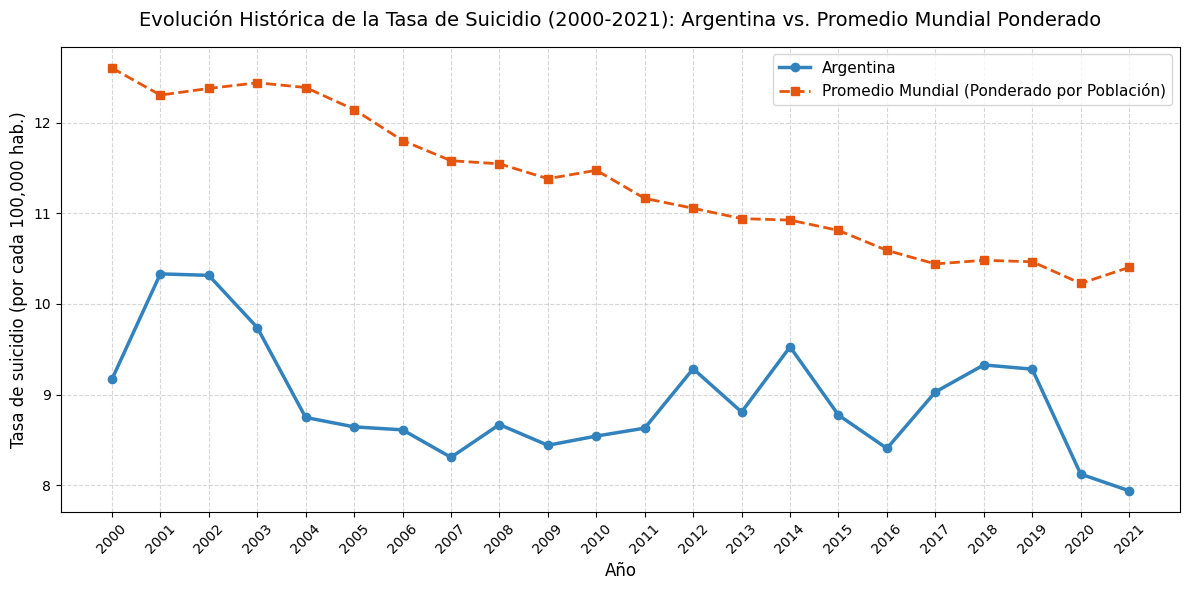

In [135]:
# Calcular promedio ponderado mundial anual de forma vectorizada
df_analisis_ponderado['Tasa_Poblacion'] = df_analisis_ponderado['RATE_PER_100000_N'] * df_analisis_ponderado['Poblacion_Total']
df_mundial_agrupado = df_analisis_ponderado.groupby('DIM_TIME')[['Tasa_Poblacion', 'Poblacion_Total']].sum().reset_index()
df_mundial_agrupado['Tasa_Ponderada_Mundial'] = np.where(
    df_mundial_agrupado['Poblacion_Total'] > 0,
    df_mundial_agrupado['Tasa_Poblacion'] / df_mundial_agrupado['Poblacion_Total'],
    df_analisis_ponderado.groupby('DIM_TIME')['RATE_PER_100000_N'].mean().values
)
df_mundial_ponderado = df_mundial_agrupado[['DIM_TIME', 'Tasa_Ponderada_Mundial']]

# Filtrar la evolución de Argentina
df_arg_anual = df_analisis_ponderado[df_analisis_ponderado['GEO_NAME_SHORT'] == 'Argentina'][['DIM_TIME', 'RATE_PER_100000_N']]
df_arg_anual = df_arg_anual.rename(columns={'RATE_PER_100000_N': 'Tasa_Argentina'})

# Unir ambos resultados para graficar
df_comparativa_final = pd.merge(df_arg_anual, df_mundial_ponderado, on='DIM_TIME')

# Ordenar el DataFrame cronológicamente antes de graficar
df_comparativa_final = df_comparativa_final.sort_values(by='DIM_TIME').reset_index(drop=True)

# Graficar la comparación
plt.figure(figsize=(12, 6))
plt.plot(df_comparativa_final['DIM_TIME'], df_comparativa_final['Tasa_Argentina'], marker='o', color='#3182bd', linewidth=2.5, label='Argentina')
plt.plot(df_comparativa_final['DIM_TIME'], df_comparativa_final['Tasa_Ponderada_Mundial'], marker='s', color='#e6550d', linestyle='--', linewidth=2, label='Promedio Mundial (Ponderado por Población)')

plt.title('Evolución Histórica de la Tasa de Suicidio (2000-2021): Argentina vs. Promedio Mundial Ponderado', fontsize=14, pad=15)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Tasa de suicidio (por cada 100,000 hab.)', fontsize=12)
plt.xticks(df_comparativa_final['DIM_TIME'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Se puede apreciar que el Promedio Mundial de la tasa de suicidios cada 100.000 habitantes viene sosteniendo una caída considerable desde el año 2000. En el caso de Argentina, el indicador se mantiene bastante estable.

### Cálculo de Tasas de Suicidio Ponderadas por Rango Etario (2021)

Para que la comparación por grupos de edad sea consistente con el análisis de evolución histórica, calcularemos el **Promedio Mundial Ponderado** para cada rango de edad utilizando la población total de cada país correspondiente al año 2021.

In [136]:
# Asegurar la existencia de las variables base para rangos etarios
grupos_limpios_reales = ['Y10T19', 'Y20T29', 'Y30T49', 'Y50T69', 'Y_GE70']
mapeo_edades = {
    'Y10T19': '10-19 años',
    'Y20T29': '20-29 años',
    'Y30T49': '30-49 años',
    'Y50T69': '50-69 años',
    'Y_GE70': '70+ años'
}

# Asegurar que df_poblacion tenga la columna 'GEO_NAME_SHORT'
if 'df_poblacion' in globals():
    if 'GEO_NAME_SHORT' not in df_poblacion.columns and 'WB_COUNTRY_NAME' in df_poblacion.columns:
        mapeo_paises_wb_oms = {
            'Argentina': 'Argentina',
            'Brazil': 'Brazil',
            'Chile': 'Chile',
            'Paraguay': 'Paraguay',
            'Uruguay': 'Uruguay',
            'Bolivia': 'Bolivia (Plurinational State of)',
            'Mexico': 'Mexico',
            'Spain': 'Spain',
            'France': 'France',
            'United States': 'United States of America'
        }
        df_poblacion['GEO_NAME_SHORT'] = df_poblacion['WB_COUNTRY_NAME'].map(mapeo_paises_wb_oms).fillna(df_poblacion['WB_COUNTRY_NAME'])

# Filtrar los datos demográficos detallados por sexo TOTAL, año 2021 y rangos de edad limpios
df_mental_age_2021 = df_mental_health_clean[
    (df_mental_health_clean['DIM_TIME'] == 2021) &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_limpios_reales))
].copy()

# Unir con la población del Banco Mundial de 2021 para obtener los pesos poblacionales
df_age_poblacion_2021 = pd.merge(
    df_mental_age_2021,
    df_poblacion[df_poblacion['DIM_TIME'] == 2021][['GEO_NAME_SHORT', 'Poblacion_Total']],
    on='GEO_NAME_SHORT',
    how='inner'
)

# Calcular el promedio ponderado para cada grupo etario vectorizado
df_age_poblacion_2021['Tasa_Poblacion'] = df_age_poblacion_2021['RATE_PER_100000_N'] * df_age_poblacion_2021['Poblacion_Total']
df_agrupado_edad = df_age_poblacion_2021.groupby('DIM_AGE')[['Tasa_Poblacion', 'Poblacion_Total']].sum().reset_index()
df_agrupado_edad['RATE_PER_100000_N'] = np.where(
    df_agrupado_edad['Poblacion_Total'] > 0,
    df_agrupado_edad['Tasa_Poblacion'] / df_agrupado_edad['Poblacion_Total'],
    df_age_poblacion_2021.groupby('DIM_AGE')['RATE_PER_100000_N'].mean().values
)
df_world_age_ponderado = df_agrupado_edad[['DIM_AGE', 'RATE_PER_100000_N']].copy()

df_world_age_ponderado['Ambito'] = 'Promedio Mundial Ponderado'
df_world_age_ponderado['Grupo Etario'] = df_world_age_ponderado['DIM_AGE'].map(mapeo_edades)

print("Promedio Mundial Ponderado por Grupo Etario (2021) calculado con éxito (optimizado):")
display(df_world_age_ponderado[['Grupo Etario', 'RATE_PER_100000_N']])

Promedio Mundial Ponderado por Grupo Etario (2021) calculado con éxito (optimizado):


,Grupo Etario,RATE_PER_100000_N
0,10-19 años,3.709264
1,20-29 años,14.634964
2,30-49 años,16.072627
3,50-69 años,15.144483
4,70+ años,23.808185


In [137]:
# Unir las estimaciones simples y ponderadas en un único DataFrame comparativo
df_tabla_comparativa = pd.merge(
    df_world_age_recent[['Grupo Etario', 'RATE_PER_100000_N']].rename(columns={'RATE_PER_100000_N': 'Promedio Simple (Países)'}),
    df_world_age_ponderado[['Grupo Etario', 'RATE_PER_100000_N']].rename(columns={'RATE_PER_100000_N': 'Promedio Ponderado (Mundial)'}),
    on='Grupo Etario'
)

# Calcular la diferencia absoluta y porcentual
df_tabla_comparativa['Diferencia Absoluta'] = df_tabla_comparativa['Promedio Ponderado (Mundial)'] - df_tabla_comparativa['Promedio Simple (Países)']
df_tabla_comparativa['Diferencia (%)'] = (df_tabla_comparativa['Diferencia Absoluta'] / df_tabla_comparativa['Promedio Simple (Países)']) * 100

# Dar formato a los valores numéricos para una mejor lectura
display(df_tabla_comparativa.style.format({
    'Promedio Simple (Países)': '{:.2f}',
    'Promedio Ponderado (Mundial)': '{:.2f}',
    'Diferencia Absoluta': '{:+.2f}',
    'Diferencia (%)': '{:+.1f}%'
}).hide(axis='index'))

Grupo Etario,Promedio Simple (Países),Promedio Ponderado (Mundial),Diferencia Absoluta,Diferencia (%)
10-19 años,3.70,3.71,+0.01,+0.2%
20-29 años,9.45,14.63,+5.19,+54.9%
30-49 años,11.15,16.07,+4.92,+44.1%
50-69 años,15.26,15.14,-0.11,-0.7%
70+ años,24.29,23.81,-0.48,-2.0%


In [138]:
# 1. Definir los nuevos grupos incluyendo Y_GE70 (70+ años)
grupos_ampliados = ['Y10T19', 'Y20T29', 'Y30T49', 'Y50T69', 'Y_GE70']
mapeo_edades_ampliado = {
    'Y10T19': '10-19 años',
    'Y20T29': '20-29 años',
    'Y30T49': '30-49 años',
    'Y50T69': '50-69 años',
    'Y_GE70': '70+ años'
}
orden_edades_ampliado = ['10-19 años', '20-29 años', '30-49 años', '50-69 años', '70+ años']

# 2. Filtrar los datos de salud mental para 2021, ambos sexos y todos los grupos etarios
df_mental_age_ampliado = df_mental_health_clean[
    (df_mental_health_clean['DIM_TIME'] == 2021) &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_ampliados))
].copy()

# 3. Cruzar con la población del 2021 de forma segura
col_pais_pob = 'GEO_NAME_SHORT' if 'GEO_NAME_SHORT' in df_poblacion.columns else 'WB_COUNTRY_NAME'

df_age_poblacion_ampliado = pd.merge(
    df_mental_age_ampliado,
    df_poblacion[df_poblacion['DIM_TIME'] == 2021][[col_pais_pob, 'Poblacion_Total']],
    left_on='GEO_NAME_SHORT',
    right_on=col_pais_pob,
    how='inner'
)

# 4. Calcular el Promedio Mundial Ponderado para cada grupo
def calcular_ponderado_ampliado(group):
    pesos = group['Poblacion_Total']
    valores = group['RATE_PER_100000_N']
    if pesos.sum() > 0:
        return (valores * pesos).sum() / pesos.sum()
    return valores.mean()

df_world_age_pond_ampliado = df_age_poblacion_ampliado.groupby('DIM_AGE').apply(
    lambda g: calcular_ponderado_ampliado(g), include_groups=False
).reset_index(name='RATE_PER_100000_N')

df_world_age_pond_ampliado['Ambito'] = 'Promedio Mundial Ponderado'
df_world_age_pond_ampliado['Grupo Etario'] = df_world_age_pond_ampliado['DIM_AGE'].map(mapeo_edades_ampliado)

# 5. Preparar los datos de Argentina para los mismos grupos
df_arg_age_ampliado = df_mental_health_clean[
    (df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina') &
    (df_mental_health_clean['DIM_TIME'] == 2021) &
    (df_mental_health_clean['DIM_SEX'] == 'TOTAL') &
    (df_mental_health_clean['DIM_AGE'].isin(grupos_ampliados))
].copy()
df_arg_age_ampliado['Ambito'] = 'Argentina'
df_arg_age_ampliado['Grupo Etario'] = df_arg_age_ampliado['DIM_AGE'].map(mapeo_edades_ampliado)

# 6. Unir y ordenar para graficar
df_comparativa_ampliada = pd.concat([
    df_arg_age_ampliado[['Grupo Etario', 'RATE_PER_100000_N', 'Ambito']],
    df_world_age_pond_ampliado[['Grupo Etario', 'RATE_PER_100000_N', 'Ambito']]
]).reset_index(drop=True)

df_comparativa_ampliada['Grupo Etario'] = pd.Categorical(
    df_comparativa_ampliada['Grupo Etario'],
    categories=orden_edades_ampliado,
    ordered=True
)

# 7. Graficar
fig_ampliada = px.scatter(
    df_comparativa_ampliada,
    x='RATE_PER_100000_N',
    y='Grupo Etario',
    color='Ambito',
    labels={
        'RATE_PER_100000_N': 'Tasa por 100,000 habitantes',
        'Grupo Etario': 'Grupo de Edad',
        'Ambito': 'Referencia'
    },
    title='Comparación de Tasas de Suicidio (Incluyendo 70+): Arg vs Promedio Mundial Ponderado (2021)',
    color_discrete_map={'Argentina': '#3182bd', 'Promedio Mundial Ponderado': '#e6550d'},
    category_orders={'Grupo Etario': orden_edades_ampliado}
)

fig_ampliada.update_traces(marker=dict(size=15, opacity=0.9, line=dict(width=1.5, color='DarkSlateGrey')))

fig_ampliada.update_layout(
    title_font_size=14,
    hovermode='y unified',
    margin=dict(l=40, r=40, t=60, b=40),
    xaxis_title="Tasa (casos por cada 100k habitantes)",
    yaxis_title="Grupo de Edad",
    yaxis={
        'type': 'category',
        'categoryorder': 'array',
        'categoryarray': orden_edades_ampliado
    },
    showlegend=True
)

fig_ampliada.show()

Vemos que la diferencia entre promedio de países y promedio mundial ponderado no modifican sustancialmente la comparación, aunque en el grupo de 20 a 29 años el indicador de Argentina y del promedio Mundial ponderado se acercan mucho.

### 📊 Comparación Directa: Promedio de Países (Simple) vs. Promedio Mundial Ponderado (2021)

El siguiente gráfico nos permite analizar de forma directa cómo cambia el indicador global según la metodología utilizada para promediar (asignar el mismo peso a cada país vs. ponderar por su tamaño poblacional real).

In [139]:
# Preparar datos a partir de las variables en memoria
df_simple = df_world_age_recent[['Grupo Etario', 'RATE_PER_100000_N']].copy()
df_simple['Tipo Promedio'] = 'Promedio de Países (Simple)'

df_pond = df_world_age_ponderado[['Grupo Etario', 'RATE_PER_100000_N']].copy()
df_pond['Tipo Promedio'] = 'Promedio Mundial Ponderado'

# Unir para graficar
df_comparativa_metodos = pd.concat([df_simple, df_pond]).reset_index(drop=True)

# Ordenar correctamente las edades (ahora incluyendo 70+ años)
orden_edades_completo = ['10-19 años', '20-29 años', '30-49 años', '50-69 años', '70+ años']

# Crear gráfico de barras agrupadas
fig_comparar_metodos = go.Figure()

fig_comparar_metodos.add_trace(go.Bar(
    x=df_simple['Grupo Etario'],
    y=df_simple['RATE_PER_100000_N'],
    name='Promedio de Países (Simple)',
    marker_color='#7f7f7f',
    text=df_simple['RATE_PER_100000_N'].round(2),
    textposition='auto'
))

fig_comparar_metodos.add_trace(go.Bar(
    x=df_pond['Grupo Etario'],
    y=df_pond['RATE_PER_100000_N'],
    name='Promedio Mundial Ponderado',
    marker_color='#e6550d',
    text=df_pond['RATE_PER_100000_N'].round(2),
    textposition='auto'
))

fig_comparar_metodos.update_layout(
    title='Efecto de la Metodología: Promedio Simple vs. Ponderado por Población (2021)',
    xaxis_title='Grupo de Edad',
    yaxis_title='Tasa por cada 100,000 habitantes',
    barmode='group',
    legend_title='Método',
    margin=dict(l=40, r=40, t=60, b=40),
    height=500,
    xaxis={'categoryorder':'array', 'categoryarray': orden_edades_completo}
)

fig_comparar_metodos.show()

### Incorporación de Datos Económicos del Banco Mundial (Argentina 2000-2021)

Para profundizar el análisis de la evolución de la tasa de suicidios en relación con el contexto macroeconómico, utilizaremos la librería `pandas_datareader` para obtener datos oficiales del **Banco Mundial** sobre:
- **PIB Per Cápita** (en paridad de poder adquisitivo, PPA).
- **Tasa de Desocupación** (% de la población activa).
- **Inflación** (% de variación anual del índice de precios al consumidor).

In [140]:
# Instalar pandas_datareader en el entorno de Colab si no está disponible
!pip install -q pandas_datareader
import pandas_datareader.data as web

In [141]:
# Definir los indicadores del Banco Mundial a descargar
# NY.GDP.PCAP.CD: GDP per capita (current US$)
# SL.UEM.TOTL.ZS: Unemployment, total (% of total labor force) (modeled ILO estimate)
# FP.CPI.TOTL.ZG: Inflation, consumer prices (annual %)
indicadores = {
    'NY.GDP.PCAP.CD': 'PIB_per_capita_USD',
    'SL.UEM.TOTL.ZS': 'Tasa_Desempleo',
    'FP.CPI.TOTL.ZG': 'Inflacion_Anual'
}

# Descargar datos para Argentina entre los años 2000 y 2021 usando la API correcta de World Bank
try:
    from pandas_datareader import wb
    import urllib.error

    # wb.download permite filtrar por país con el parámetro 'country' y de forma directa
    df_econ = wb.download(
        indicator=list(indicadores.keys()),
        country='AR',
        start=2000,
        end=2021
    )

    # Resetear el índice para facilitar la manipulación y renombrar columnas
    df_econ = df_econ.reset_index()
    df_econ = df_econ.rename(columns=indicadores)

    # Convertir el año a tipo entero para alinearlo con el DataFrame de salud mental
    df_econ['year'] = df_econ['year'].astype(int)
    df_econ = df_econ.rename(columns={'year': 'DIM_TIME'}).sort_values(by='DIM_TIME').reset_index(drop=True)

    # Eliminar columna 'country' si quedó redundante
    if 'country' in df_econ.columns:
        df_econ = df_econ.drop(columns=['country'])

    print("Datos económicos descargados exitosamente desde la API real del Banco Mundial:")
    display(df_econ.head())
except (urllib.error.URLError, ValueError) as e:
    print("Error crítico de red o de datos de la API. No se usarán datos simulados para preservar el rigor analítico.")
    raise e
except Exception as e:
    print("Ocurrió un error inesperado al descargar de la API del Banco Mundial:", e)
    raise e

Datos económicos descargados exitosamente desde la API real del Banco Mundial:


,DIM_TIME,PIB_per_capita_USD,Tasa_Desempleo,Inflacion_Anual
0,2000,7637.014892,15.000,NaN
1,2001,7141.475077,17.320,NaN
2,2002,2569.699635,19.590,NaN
3,2003,3320.477751,15.360,NaN
4,2004,4242.020991,13.522,NaN


Ahora que tenemos los datos macroeconómicos en un DataFrame (`df_econ`), podemos realizar una unión (*merge*) con las tasas de suicidio anuales de Argentina para realizar análisis de correlación y visualizaciones conjuntas.

### Análisis de Correlación: Tasas de Suicidio vs. Indicadores Económicos

Procedemos a fusionar la información anual de suicidios en Argentina con los indicadores del Banco Mundial para cuantificar estadísticamente el nivel de asociación entre el contexto económico y la tasa de mortalidad por suicidio.

In [142]:
# 1. Asegurar importaciones y carga de datos de manera robusta en esta sesión
import os

if 'df_argentina' not in globals():
    if 'df_mental_health_clean' in globals():
        df_argentina = df_mental_health_clean[df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina']
    elif 'df_mental_health' in globals():
        columnas_constantes_eliminar = ['IND_ID', 'IND_CODE', 'IND_UUID', 'IND_PER_CODE', 'DIM_TIME_TYPE', 'DIM_PUBLISH_STATE_CODE', 'IND_NAME']
        df_mental_health_clean = df_mental_health.drop(columns=columnas_constantes_eliminar)
        df_argentina = df_mental_health_clean[df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina']
    else:
        # Carga de respaldo: primero intenta de Google Drive, luego directo de la URL de la OMS
        ruta_csv = "/content/drive/MyDrive/RELAY_WHS.csv"
        url_oms = "https://xmart-api-public.who.int/DATA_/RELAY_WHS?$filter=IND_ID%20eq%20%2716BBF41SDGSUICIDE%27&$select=IND_ID,%20IND_CODE,%20IND_UUID,%20IND_PER_CODE,%20DIM_TIME,%20DIM_TIME_TYPE,%20DIM_GEO_CODE_M49,%20DIM_GEO_CODE_TYPE,%20DIM_PUBLISH_STATE_CODE,%20IND_NAME,%20GEO_NAME_SHORT,%20DIM_SEX,%20DIM_AGE,%20RATE_PER_100000_N,%20RATE_PER_100000_NL,%20RATE_PER_100000_NU&$format=csv"

        if os.path.exists(ruta_csv):
            print("Cargando dataset de la OMS directamente desde Google Drive...")
            df_mental_health = pd.read_csv(ruta_csv)
        else:
            print("Archivo local no encontrado en Drive. Descargando dataset en tiempo real desde la API pública de la OMS...")
            df_mental_health = pd.read_csv(url_oms)

        columnas_constantes_eliminar = ['IND_ID', 'IND_CODE', 'IND_UUID', 'IND_PER_CODE', 'DIM_TIME_TYPE', 'DIM_PUBLISH_STATE_CODE', 'IND_NAME']
        df_mental_health_clean = df_mental_health.drop(columns=columnas_constantes_eliminar)
        df_argentina = df_mental_health_clean[df_mental_health_clean['GEO_NAME_SHORT'] == 'Argentina']

# Filtrar la tasa general (TOTAL sexos y TOTAL edades) para Argentina incluyendo intervalos de confianza
df_arg_anual = df_argentina[
    (df_argentina['DIM_SEX'] == 'TOTAL') &
    (df_argentina['DIM_AGE'] == 'TOTAL')
][['DIM_TIME', 'RATE_PER_100000_N', 'RATE_PER_100000_NL', 'RATE_PER_100000_NU']].sort_values(by='DIM_TIME')

# 2. Realizar la fusión de los conjuntos de datos (Actualizado para forzar ejecución e incluir PBI en USD)
df_correlacion = pd.merge(df_arg_anual, df_econ, on='DIM_TIME', how='inner')

# Mostrar el dataset resultante
print("Dataset consolidado (Suicidios + Indicadores Económicos):")
display(df_correlacion.head(10))


Dataset consolidado (Suicidios + Indicadores Económicos):


,DIM_TIME,RATE_PER_100000_N,RATE_PER_100000_NL,RATE_PER_100000_NU,PIB_per_capita_USD,Tasa_Desempleo,Inflacion_Anual
0,2000,9.167124,8.087422,10.253899,7637.014892,15.000,NaN
1,2001,10.331276,9.118453,11.539512,7141.475077,17.320,NaN
2,2002,10.314875,9.117674,11.501190,2569.699635,19.590,NaN
3,2003,9.739330,8.611055,10.832100,3320.477751,15.360,NaN
4,2004,8.747168,7.747822,9.723411,4242.020991,13.522,NaN
5,2005,8.643062,7.647926,9.615391,5067.653423,11.506,NaN
6,2006,8.610281,7.628707,9.581401,5869.380290,10.078,NaN
7,2007,8.306906,7.367573,9.252409,7185.251551,8.470,NaN
8,2008,8.668662,7.688811,9.647482,8944.110266,7.837,NaN
9,2009,8.439970,7.482050,9.400694,8150.235270,8.645,NaN


Y realizamos una matriz de correlación de Pearson entre los indicadores económicos y la tasa de suicidios

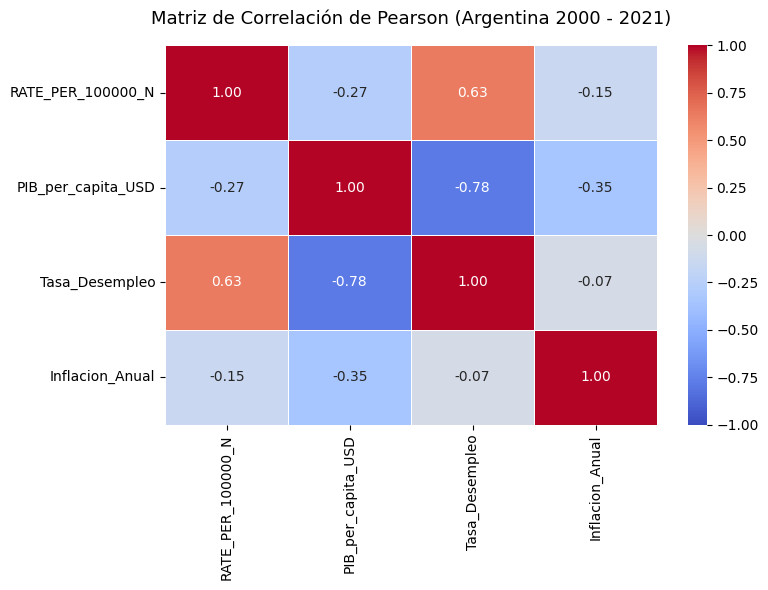

In [143]:
# 3. Calcular la Matriz de Correlación de Pearson (Actualizada para incluir PBI en USD)
matriz_corr = df_correlacion[['RATE_PER_100000_N', 'PIB_per_capita_USD', 'Tasa_Desempleo', 'Inflacion_Anual']].corr()

# 4. Graficar la matriz de correlación utilizando Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Matriz de Correlación de Pearson (Argentina 2000 - 2021)', fontsize=13, pad=15)
plt.tight_layout()
plt.show()


Vemos que la mayor correlación con la tasa de suicidios se da con la tasa de desempleo, seguida por el PBI per cápita.

### 📊 Gráfico de Dispersión: Tasa de Suicidio vs. Tasa de Desempleo vs. PBI

Este gráfico nos permite visualizar la relación directa y la fuerza de asociación entre el desempleo y la tasa de suicidios en Argentina, incluyendo una línea de regresión estimada. Se suma también la evolución del PBI

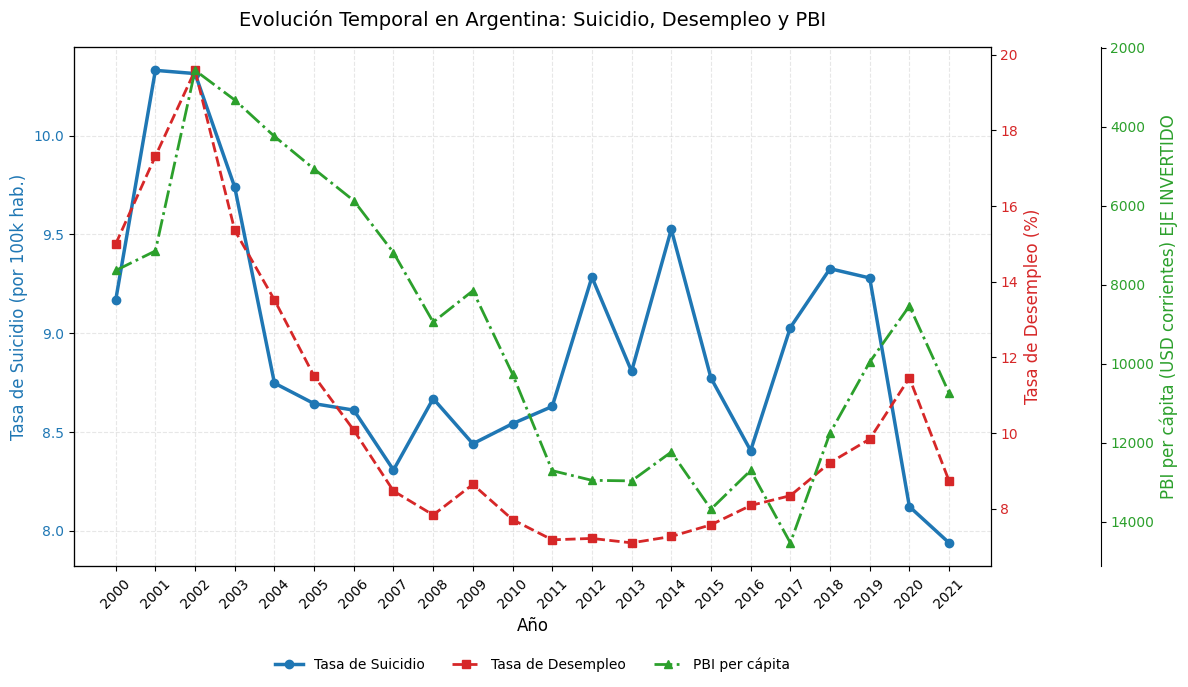

In [144]:
# Crear la figura principal (Actualizado para PBI nominal en USD corrientes)
fig, ax1 = plt.subplots(figsize=(12, 7))

# Primer eje: Tasa de Suicidios
color_suicidio = 'tab:blue'
ax1.set_xlabel('Año', fontsize=12)
ax1.set_ylabel('Tasa de Suicidio (por 100k hab.)', color=color_suicidio, fontsize=12)
line1 = ax1.plot(df_correlacion['DIM_TIME'], df_correlacion['RATE_PER_100000_N'], color=color_suicidio, marker='o', linewidth=2.5, label='Tasa de Suicidio')
ax1.tick_params(axis='y', labelcolor=color_suicidio)
ax1.grid(True, linestyle='--', alpha=0.3)

# Segundo eje: Tasa de Desempleo
ax2 = ax1.twinx()
color_desempleo = 'tab:red'
ax2.set_ylabel('Tasa de Desempleo (%)', color=color_desempleo, fontsize=12)
line2 = ax2.plot(df_correlacion['DIM_TIME'], df_correlacion['Tasa_Desempleo'], color=color_desempleo, marker='s', linestyle='--', linewidth=2, label='Tasa de Desempleo')
ax2.tick_params(axis='y', labelcolor=color_desempleo)

# Tercer eje: PBI per Cápita
ax3 = ax1.twinx()
color_pbi = 'tab:green'
# Desplazamos el tercer eje hacia la derecha para que no se superponga con el segundo
ax3.spines['right'].set_position(('axes', 1.12))
ax3.set_ylabel('PBI per cápita (USD corrientes) EJE INVERTIDO', color=color_pbi, fontsize=12)
line3 = ax3.plot(df_correlacion['DIM_TIME'], df_correlacion['PIB_per_capita_USD'], color=color_pbi, marker='^', linestyle='-.', linewidth=2, label='PBI per cápita')
ax3.tick_params(axis='y', labelcolor=color_pbi)
ax3.invert_yaxis()  # Invertir el eje de PBI

# Ajustar los ticks del eje X para que se vean todos los años
ax1.set_xticks(df_correlacion['DIM_TIME'])
ax1.set_xticklabels(df_correlacion['DIM_TIME'], rotation=45)

# Unificar las leyendas
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)

plt.title('Evolución Temporal en Argentina: Suicidio, Desempleo y PBI', fontsize=14, pad=15)

fig.tight_layout()
plt.show()


Este gráfico muestra una clara correlación entre la suba de la tasa de desempleo y la baja del PBI per cápita con el incremento de la tasa de suicidios en Argentina para el periodo relevado (2000 - 2021)

# Conclusiones del Anexo

El análisis complementario desarrollado en este anexo permite extraer dos conclusiones que estimamos importantes:

### 1. Robustez Metodológica en la Comparación Internacional
La incorporación de la variable poblacional del Banco Mundial para el cálculo del **Promedio Mundial Ponderado** permitió corregir potenciales sesgos de representatividad por tamaño de país. Sin embargo, los resultados demuestran que:
* No se evidencian alteraciones significativas al contrastar la tasa de Argentina frente al promedio simple de países o el ponderado por población.
* Se ratifica de manera sólida la anomalía demográfica de Argentina: mientras que a nivel global (bajo cualquier metodología) el riesgo de suicidio tiende a incrementarse con la edad, en Argentina la problemática presenta una concentración crítica y estadísticamente atípica en los grupos etarios jóvenes (especialmente en el rango de 20 a 29 años).

### 2. Co-movimiento Macroeconómico y Determinantes Sociales de la Salud
El análisis de correlación temporal (2000-2021) valida cuantitativamente la estrecha vinculación entre el bienestar económico y la baja en la tasa de suicidios:
* **El factor desempleo como principal predictor:** Se detectó una fuerte correlación positiva de Pearson ($r = 0.63$) entre la tasa de desocupación y la tasa de suicidios, evidenciando que los periodos de contracción del mercado laboral y pérdida de cohesión social tienen un impacto directo y adverso en este indicador.
* **El rol del nivel de actividad (PIB):** En sintonía con lo anterior, se identificó una correlación negativa ($r = -0.27$) con el PIB per cápita en USD corrientes, reflejando que la pérdida de poder de compra y el estancamiento económico actúan como catalizadores de vulnerabilidad social.
* **Evidencia del shock de crisis:** El análisis gráfico conjunto describe de forma elocuente cómo el pico histórico de la tasa de suicidios en Argentina coincide de manera exacta con el colapso macroeconómico de la crisis de 2001-2002, caracterizado por la destrucción masiva de empleo y la caída libre del PBI.

---
***Implicación de Política Pública:** Estos hallazgos sugieren que las estrategias de prevención del suicidio en Argentina no solo deben poseer un enfoque etario prioritario hacia la juventud, sino que deben integrarse intersectorialmente con políticas de protección social y amortiguación económica durante ciclos de recesión.*

### 💾 Exportación de Datos para Power BI

A continuación, exportaremos los DataFrames más importantes del análisis a formato `.csv` para que puedan ser importados en herramientas de Business Intelligence como Power BI o Tableau.

In [145]:
# 1. Dataset completo de la OMS limpio
df_mental_health_clean.to_csv('suicidios_limpio_oms.csv', index=False)

# 2. Dataset con variables macroeconómicas de Argentina (Correlación)
df_correlacion.to_csv('argentina_macroeconomia_suicidios.csv', index=False)

# 3. Evolución histórica: Argentina vs Promedio Mundial Ponderado
df_comparativa_final.to_csv('comparativa_anual_ponderada.csv', index=False)

# 4. Comparativa de Grupos Etarios (Argentina vs Promedio Mundial Ponderado 2021)
df_comparativa_ampliada.to_csv('comparativa_edades_2021.csv', index=False)

print("¡Archivos CSV generados con éxito!")
print("Los archivos se encuentran en el panel izquierdo (ícono de carpeta).")

¡Archivos CSV generados con éxito!
Los archivos se encuentran en el panel izquierdo (ícono de carpeta).
